In [ ]:
import pandas as pd
from google.colab import files

uploaded = files.upload()
df = pd.read_csv("iris.txt")

print(df.head())
print(df.shape)
print(df.columns)
print(df["species"].value_counts())

Saving iris.txt to iris.txt
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
(150, 5)
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [ ]:
# Separate input features
X = df.drop("species", axis=1)

# Separate target
y = df["species"]

# Display results
print("Input features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input features:
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

Target:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [4]:

from sklearn.model_selection import train_test_split

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training data: (120, 4)
Testing data: (30, 4)
Training targets: (120,)
Testing targets: (30,)


In [5]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Learn from training data and scale it
X_train_scaled = scaler.fit_transform(X_train)

# Scale testing data
X_test_scaled = scaler.transform(X_test)

# Display results
print("Before scaling:")
print(X_train.head())

print("\nAfter scaling:")
print(X_train_scaled[:5])

Before scaling:
     sepal_length  sepal_width  petal_length  petal_width
8             4.4          2.9           1.4          0.2
106           4.9          2.5           4.5          1.7
76            6.8          2.8           4.8          1.4
9             4.9          3.1           1.5          0.1
89            5.5          2.5           4.0          1.3

After scaling:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]


In [6]:

from sklearn.linear_model import LogisticRegression

# Create the model
model_lr = LogisticRegression(max_iter=1000)

# Train the model
model_lr.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [7]:
# Predict flower species
y_pred_lr = model_lr.predict(X_test_scaled)

# Display first 10 predictions
print(y_pred_lr[:10])

['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


In [8]:
from sklearn.metrics import accuracy_score

# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy * 100, "%")

Logistic Regression Accuracy: 93.33333333333333 %


In [9]:
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(random_state=42)

model_dt.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [10]:
y_pred_dt = model_dt.predict(X_test)

print("Decision Tree Predictions:")
print(y_pred_dt)

Decision Tree Predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


In [11]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt * 100, "%")

Decision Tree Accuracy: 93.33333333333333 %


In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision_lr = precision_score(y_test, y_pred_lr, average="weighted")
recall_lr = recall_score(y_test, y_pred_lr, average="weighted")
f1_lr = f1_score(y_test, y_pred_lr, average="weighted")

print("Logistic Regression Metrics")
print("Precision:", precision_lr)
print("Recall:", recall_lr)
print("F1-Score:", f1_lr)

Logistic Regression Metrics
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1-Score: 0.9333333333333333


In [13]:
precision_dt = precision_score(y_test, y_pred_dt, average="weighted")
recall_dt = recall_score(y_test, y_pred_dt, average="weighted")
f1_dt = f1_score(y_test, y_pred_dt, average="weighted")

print("Decision Tree Metrics")
print("Precision:", precision_dt)
print("Recall:", recall_dt)
print("F1-Score:", f1_dt)

Decision Tree Metrics
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1-Score: 0.9333333333333333


In [14]:
from sklearn.metrics import confusion_matrix

cm_lr = confusion_matrix(y_test, y_pred_lr)

print("Logistic Regression Confusion Matrix:")
print(cm_lr)

Logistic Regression Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [15]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Decision Tree Confusion Matrix:")
print(cm_dt)

Decision Tree Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [16]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy, accuracy_dt],
    "Precision": [precision_lr, precision_dt],
    "Recall": [recall_lr, recall_dt],
    "F1-Score": [f1_lr, f1_dt]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression  0.933333   0.933333  0.933333  0.933333
1        Decision Tree  0.933333   0.933333  0.933333  0.933333


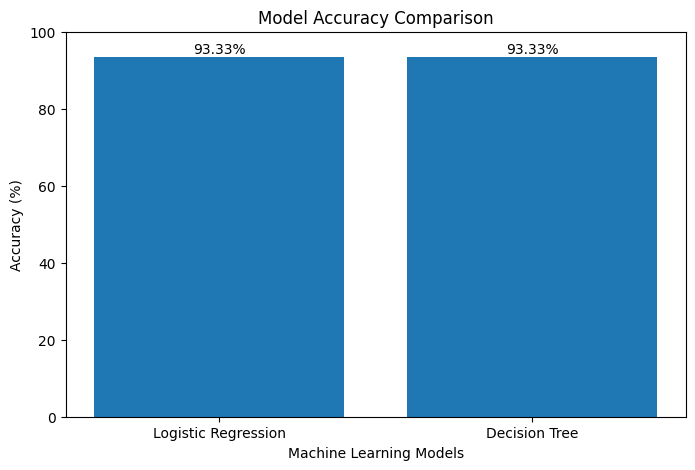

In [17]:
import matplotlib.pyplot as plt

models = ["Logistic Regression", "Decision Tree"]
accuracies = [accuracy * 100, accuracy_dt * 100]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

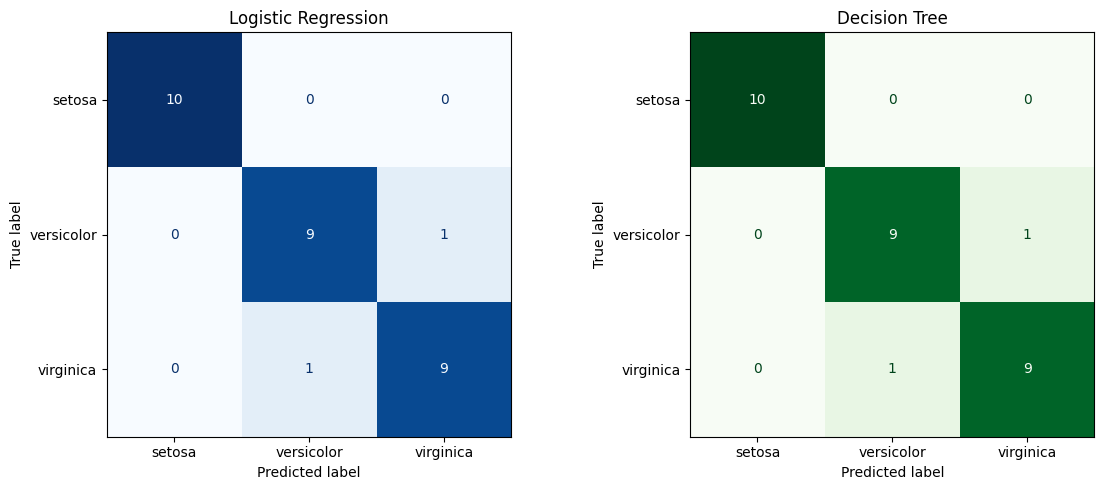

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=model_lr.classes_
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=model_dt.classes_
).plot(ax=axes[1], cmap="Greens", colorbar=False)

axes[1].set_title("Decision Tree")

plt.tight_layout()
plt.show()